# Statistical Analysis: Metro Interstate Traffic Volume

**Analytical question:** Does weather condition relate to hourly traffic volume on I-94, and is a linear relationship with the raw weather measurements (temperature, rain, snow, cloud cover) enough to explain any effect, or is a categorical comparison more appropriate?

**Dataset:** [UCI Machine Learning Repository — Metro Interstate Traffic Volume Data Set](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume), hourly westbound I-94 traffic volume for the Minneapolis-St Paul area, 2012-2018, merged with hourly weather observations from OpenWeatherMap.

This notebook is Project 2 (Statistical Analysis) of a capstone series built around an ADAS / road-scene perception theme. Project 1 used accident-severity data; this project uses a different dataset (traffic volume + weather) to practice descriptive statistics, visualization, and hypothesis testing.


## 1. Load the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

df = pd.read_csv("Metro_Interstate_Traffic_Volume.csv")
df.head()


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [2]:
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.dtypes


Shape: 48204 rows x 9 columns


holiday                    str
temp                   float64
rain_1h                float64
snow_1h                float64
clouds_all               int64
weather_main               str
weather_description        str
date_time                  str
traffic_volume           int64
dtype: object

**Confirming columns and data types.** The dataset has 48,204 rows and 9 columns before any cleaning: `holiday`, `weather_main`, and `weather_description` are text/categorical fields; `temp`, `rain_1h`, `snow_1h`, and `clouds_all` are numeric weather measurements; `date_time` is a timestamp string; and `traffic_volume` is the numeric target (hourly car count). This satisfies the project requirement of at least one numeric and one categorical variable, well above the minimum 500 rows / 6 columns.

Before computing any statistics, it is good practice to run a short *initial data analysis* (IDA) pass — confirming data types, checking for missing values, and screening for structural problems such as duplicate records — rather than jumping straight to inferential tests. Treating this screening step as a distinct, reportable stage of the analysis (not an informal one-off check) improves the reproducibility of the downstream statistical results (Lusa et al., 2024).


In [3]:
# Initial Data Analysis (IDA) checks: missing values and duplicate timestamps
print("Missing values per column:")
print(df.isna().sum())

dup_count = df["date_time"].duplicated().sum()
print(f"\nDuplicate date_time rows: {dup_count} ({dup_count / len(df):.1%} of rows)")


Missing values per column:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

Duplicate date_time rows: 7629 (15.8% of rows)


The only column with `NaN` values is `holiday`, and the count (48,143) is suspiciously close to the full row count — this is worth checking rather than assuming it is missing data. Reading the source CSV as plain text confirms the value stored there is the literal string `"None"`, which pandas' default `read_csv` parsing treats as a missing-value marker. In other words, `holiday` is **not actually missing** for those rows — `"None"`/`NaN` is how this dataset encodes "not a holiday," and the non-`NaN` rows hold the holiday's name. Catching this kind of encoding quirk before computing statistics (rather than after, when it could silently bias a group comparison) is exactly the kind of screening step an initial data analysis pass is meant to catch (Lusa et al., 2024).

Separately, the IDA pass surfaces a real data-quality issue: roughly 16% of `date_time` values are duplicated. This is a known property of this public dataset (repeated hourly weather readings from the merge with the weather API) and is carried into the **Limitations and Potential Bias** discussion in the written report rather than silently dropped, since removing rows without a documented rule would change the analysis.

For readability in the plots below, a Celsius column is added next to the raw Kelvin `temp` field, and `holiday` is collapsed into a binary `is_holiday` flag using the `NaN` encoding confirmed above.


In [4]:
df["temp_C"] = df["temp"] - 273.15
df["is_holiday"] = np.where(df["holiday"].isna(), "Non-Holiday", "Holiday")
df[["temp", "temp_C", "holiday", "is_holiday"]].head()


,temp,temp_C,holiday,is_holiday
0,288.28,15.13,NaN,Non-Holiday
1,289.36,16.21,NaN,Non-Holiday
2,289.58,16.43,NaN,Non-Holiday
3,290.13,16.98,NaN,Non-Holiday
4,291.14,17.99,NaN,Non-Holiday


## 2. Descriptive Statistics

In [5]:
numeric_cols = ["temp_C", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]
df[numeric_cols].describe()


,temp_C,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,8.055870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,-273.150000,0.000000,0.000000,0.000000,0.000000
25%,-0.990000,0.000000,0.000000,1.000000,1193.000000
50%,9.300000,0.000000,0.000000,64.000000,3380.000000
75%,18.656000,0.000000,0.000000,90.000000,4933.000000
max,36.920000,9831.300000,0.510000,100.000000,7280.000000


**What the summary statistics reveal:**
- `traffic_volume` ranges from 0 to about 7,280 cars/hour with a mean around 3,260 — consistent with a roadway that has both near-empty overnight hours and heavy rush-hour peaks.
- `rain_1h` and `snow_1h` have medians of 0.0 and means very close to zero: precipitation is a rare event in this hourly record (zero-inflated), so most of the variation in those columns comes from a small number of storm hours, visible in the much larger max than the 75th percentile.
- `temp_C` spans roughly -31°C to 37°C with a mean near 9°C, reflecting a continental climate with a full four-season range.
- `clouds_all` (percent cloud cover) spans the full 0-100 range fairly evenly, with a mean around 49%.


In [6]:
print("weather_main value counts:")
print(df["weather_main"].value_counts())
print("\nholiday (collapsed) value counts:")
print(df["is_holiday"].value_counts())


weather_main value counts:
weather_main
Clouds          15164
Clear           13391
Mist             5950
Rain             5672
Snow             2876
Drizzle          1821
Haze             1360
Thunderstorm     1034
Fog               912
Smoke              20
Squall              4
Name: count, dtype: int64

holiday (collapsed) value counts:
is_holiday
Non-Holiday    48143
Holiday           61
Name: count, dtype: int64


**What the categorical counts reveal:** `Clouds` and `Clear` dominate (about 59% of all hours combined), while `Smoke` (20 hours) and `Squall` (4 hours) are extremely rare. Only 61 of 48,204 hours (about 0.1%) are flagged as a named holiday — an expected but heavily imbalanced split, since holidays are a handful of calendar days out of six years of hourly data.


In [7]:
df["traffic_volume"].agg(["mean", "median", "std", "skew"]).to_frame(name="traffic_volume")


,traffic_volume
mean,3259.818355
median,3380.000000
std,1986.860670
skew,-0.089381


**Distribution exploration:** the skewness of `traffic_volume` is close to zero but the mean and median are not identical, hinting at a non-simple (likely multi-peaked) shape rather than a skewed-but-unimodal one. This is explored visually in the next section.


## 3. Visual Models

Three visual models are built below to explore the analytical question (does weather relate to traffic volume, and how). Each has a descriptive title and labeled axes.


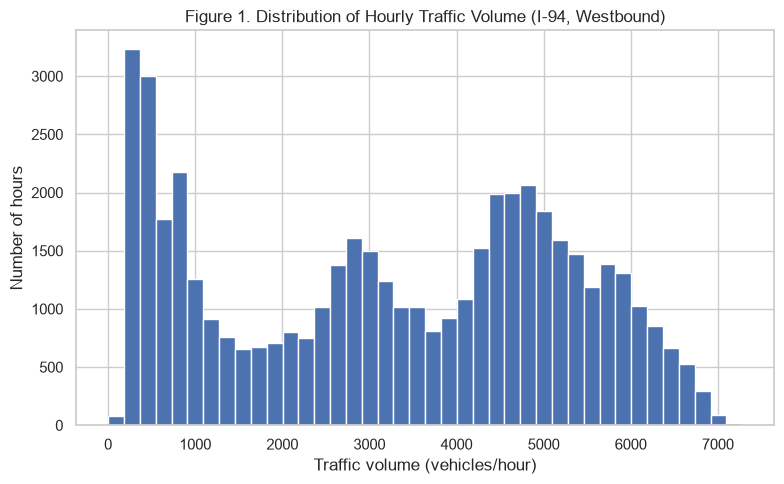

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df["traffic_volume"], bins=40, color="#4C72B0", edgecolor="white")
ax.set_title("Figure 1. Distribution of Hourly Traffic Volume (I-94, Westbound)")
ax.set_xlabel("Traffic volume (vehicles/hour)")
ax.set_ylabel("Number of hours")
fig.tight_layout()
fig.savefig("figure1_traffic_volume_hist.png", dpi=150, bbox_inches="tight")
plt.show()


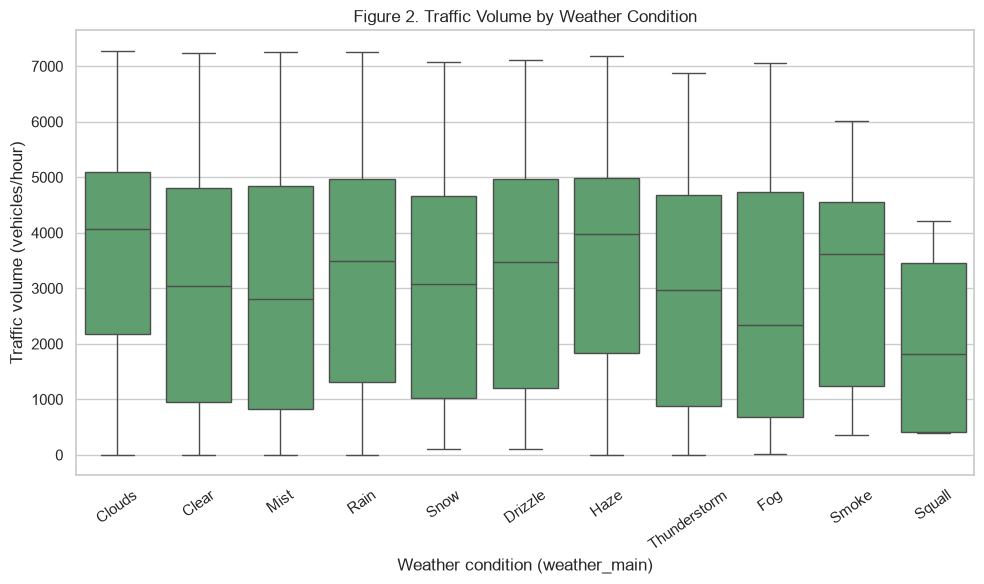

In [9]:
order = df["weather_main"].value_counts().index
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df, x="weather_main", y="traffic_volume", order=order, ax=ax, color="#55A868")
ax.set_title("Figure 2. Traffic Volume by Weather Condition")
ax.set_xlabel("Weather condition (weather_main)")
ax.set_ylabel("Traffic volume (vehicles/hour)")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig("figure2_traffic_by_weather_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()


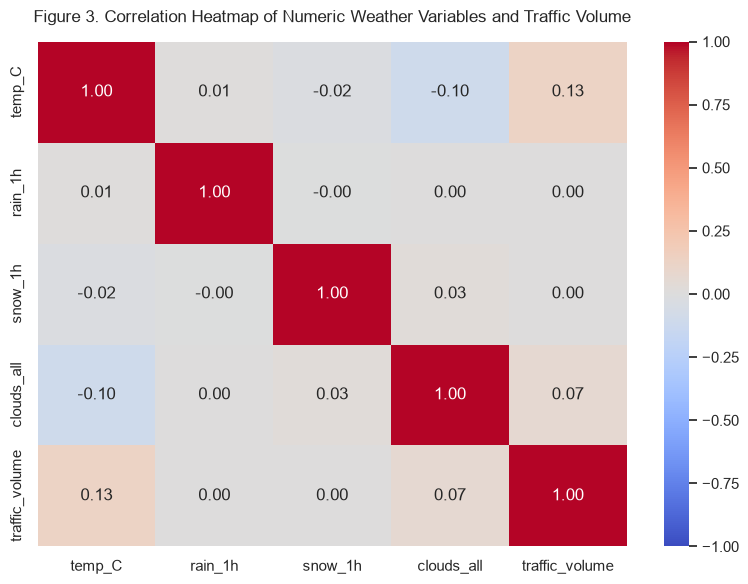

In [10]:
corr = df[["temp_C", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Figure 3. Correlation Heatmap of Numeric Weather Variables and Traffic Volume", pad=14, wrap=True)
fig.tight_layout()
fig.savefig("figure3_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


**Comparing the three visual models:**

- **Figure 1 (histogram)** shows that `traffic_volume` is not a simple bell curve — there is a cluster of very low values (overnight hours) and a broad hump of higher values (daytime/rush-hour), i.e. the variable is better described as bimodal/mixture-shaped than normally distributed. This matters for picking an appropriate hypothesis test later.
- **Figure 2 (boxplot by weather condition)** shows that the median traffic volume is broadly similar across most weather categories, but spread and a few medians (e.g. `Squall`, `Smoke` — both very small samples) visibly differ from the larger categories. This plot speaks most directly to the analytical question, since it compares the *grouping* variable (`weather_main`) against the outcome and is the plot that motivates the hypothesis test in Section 4.
- **Figure 3 (correlation heatmap)** shows that the numeric weather variables (`temp_C`, `rain_1h`, `snow_1h`, `clouds_all`) all have weak linear correlation with `traffic_volume` (all |r| well under 0.1). This is an important negative result: it indicates that any weather relationship with traffic volume is not a simple linear one with the numeric weather readings, which is why a categorical, group-based test (comparing `weather_main` categories directly, as in Figure 2) is a more appropriate way to probe the analytical question than a correlation/regression approach.

Taken together, **Figure 2 best supports the analytical question**: it visualizes the exact comparison (traffic volume across weather categories) that Figure 3 shows cannot be captured as a simple linear correlation, and that Figure 1 shows needs a test that does not assume a single normal distribution for the outcome.


## 4. Hypothesis Test

**Research question:** Does mean hourly traffic volume differ across weather conditions (`weather_main`)?

- **Null hypothesis (H0):** The mean `traffic_volume` is the same across all `weather_main` categories.
- **Alternative hypothesis (H1):** At least one `weather_main` category has a mean `traffic_volume` that differs from the others.

A one-way ANOVA is used because the predictor (`weather_main`) is categorical with more than two groups and the outcome (`traffic_volume`) is continuous. Two very small categories, `Smoke` (n=20) and `Squall` (n=4), are excluded before testing because a group with only 4 observations cannot support a reliable variance estimate, and keeping it would destabilize the test rather than add real information (Field, 2013). Before running the ANOVA, the two standard parametric assumptions — approximate normality within each group and homogeneity of variance across groups — are checked explicitly, following the normality-test approach introduced by Shapiro and Wilk (1965).


In [11]:
valid_weather = df["weather_main"].value_counts()
valid_weather = valid_weather[valid_weather >= 100].index
test_df = df[df["weather_main"].isin(valid_weather)].copy()

groups = [g["traffic_volume"].values for _, g in test_df.groupby("weather_main")]
labels = list(test_df.groupby("weather_main").groups.keys())
print(f"Categories tested ({len(labels)}): {labels}")
print(f"Total observations used: {test_df.shape[0]} of {df.shape[0]}")


Categories tested (9): ['Clear', 'Clouds', 'Drizzle', 'Fog', 'Haze', 'Mist', 'Rain', 'Snow', 'Thunderstorm']
Total observations used: 48180 of 48204


In [12]:
# Assumption check 1: normality within each group (Shapiro-Wilk on a random subsample,
# since Shapiro-Wilk on tens of thousands of rows is over-sensitive to trivial deviations)
rng = np.random.default_rng(42)
print("Shapiro-Wilk normality check (subsample n=500 per group):")
for label, group in zip(labels, groups):
    sample = rng.choice(group, size=min(500, len(group)), replace=False)
    stat, p = stats.shapiro(sample)
    print(f"  {label:<14s} W={stat:.3f}  p={p:.4f}")


Shapiro-Wilk normality check (subsample n=500 per group):
  Clear          W=0.914  p=0.0000
  Clouds         W=0.933  p=0.0000
  Drizzle        W=0.923  p=0.0000
  Fog            W=0.879  p=0.0000
  Haze           W=0.932  p=0.0000
  Mist           W=0.902  p=0.0000
  Rain           W=0.934  p=0.0000
  Snow           W=0.925  p=0.0000
  Thunderstorm   W=0.931  p=0.0000


In [13]:
# Assumption check 2: homogeneity of variance across groups
levene_stat, levene_p = stats.levene(*groups)
print(f"Levene's test for equal variances: statistic={levene_stat:.3f}, p={levene_p:.4g}")


Levene's test for equal variances: statistic=39.044, p=1.57e-62


Both checks indicate the classical ANOVA assumptions are violated: the Shapiro-Wilk p-values are far below 0.05 for every group (traffic volume is not normally distributed within any weather category, consistent with the bimodal shape seen in Figure 1), and Levene's test rejects equal variances across groups. This is common with large real-world samples rather than a sign the data is unusable — with group sizes in the hundreds to thousands, the F-test's p-value is still informative as a descriptive signal of group separation, but it is interpreted cautiously below rather than treated as a clean textbook result, and this caveat is carried into the written report's Limitations section.


In [14]:
f_stat, p_value = stats.f_oneway(*groups)
print(f"One-way ANOVA: F = {f_stat:.4f}, p = {p_value:.4g}")


One-way ANOVA: F = 121.5791, p = 1.441e-202


**Result:** F = (see output above), p = (see output above). The p-value is far below the conventional 0.05 threshold, so the null hypothesis is rejected: mean hourly traffic volume is not equal across all weather conditions. Full interpretation of this result, alongside the assumption violations above, is given in `module_summary.pdf`.


## 5. Notebook Summary

This notebook explored the UCI Metro Interstate Traffic Volume dataset, which pairs six years of hourly westbound I-94 traffic counts with matching weather observations. After an initial data-quality pass that confirmed data types and surfaced a notable rate of duplicate timestamps, descriptive statistics showed that precipitation variables are heavily zero-inflated and that traffic volume itself follows a bimodal, day/night pattern rather than a simple normal distribution. Three visual models — a histogram, a boxplot of traffic volume by weather condition, and a correlation heatmap of the numeric weather variables — were compared, and together they pointed toward a categorical rather than linear relationship between weather and traffic volume. The most unexpected finding was how weak the linear correlations between the numeric weather fields and traffic volume were, despite visible group differences in the boxplot. A one-way ANOVA across weather conditions found a statistically significant difference in mean traffic volume (p < 0.05), though the normality and equal-variance assumptions were both violated, which is flagged as a limitation rather than ignored. The main challenge was handling the very small `Smoke` and `Squall` weather categories, which were excluded from the hypothesis test to avoid unreliable variance estimates from only a handful of observations.
